# 🏠 Первые ML-модели: прогноз цен на жильё в Лондоне (чекпойнт 3)

**Тема проекта:** прогнозирование цен на недвижимость Лондона и оценка влияния факторов · годовой проект НИУ ВШЭ, ФКН, магистерская программа «Искусственный интеллект» · куратор: Чепиков Иван · исполнитель: Пичулина Анастасия

**Что в этом ноутбуке.** Выбираем ключевую метрику, строим простые модели (ориентир без ML, метод ближайших соседей KNN, линейные модели), улучшаем их подбором гиперпараметров и работой с признаками, сравниваем с более сильной моделью (градиентный бустинг LightGBM) и разбираем ошибки. Все модели проверяются одинаково честно: по времени, на будущих годах.

**Как устроено.** Тяжёлые расчёты (обучение, перебор настроек) делает скрипт `src/train_models.py`, общие функции лежат в `src/ml_utils.py`. Скрипт сохраняет результаты в `reports/ml_*.csv`, а ноутбук только читает их и рисует таблицы и графики, поэтому выполняется за секунды. Как всё пересчитать, написано в конце (раздел 11).

**Содержание**

1. Задача, цель модели и ключевая метрика
2. Данные и схема проверки по времени
3. Ориентиры без машинного обучения
4. Метод ближайших соседей (KNN)
5. Линейные модели: LinearRegression, Ridge, Lasso
6. Градиентный бустинг LightGBM (для сравнения)
7. Итоговое сравнение моделей
8. Анализ ошибок и важность признаков
9. Гипотеза: чем больше площадь, тем ниже цена за м²
10. Выводы и что дальше
11. Как воспроизвести

**Короткий словарик**

- **Фолд** — одна пара «обучение + проверка». У нас фолд 2021 = обучаемся на продажах до 2020 года включительно, проверяем на продажах 2021 года.
- **Гиперпараметр** — настройка модели, которую задаём мы, а не модель учит сама (например, число соседей k у KNN или сила регуляризации alpha у Ridge).
- **Утечка** — когда при обучении модель видит то, чего в реальности в момент прогноза знать нельзя (например, цены будущего года). Оценка с утечкой получается обманчиво хорошей.
- **log** — натуральный логарифм. Разница логарифмов ≈ относительная разница: log(1,1) ≈ 0,095, то есть ошибка «на 10%» ≈ 0,1 в логарифмах.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.max_colwidth', 120)
pd.set_option('display.float_format', '{:,.4f}'.format)

BLUE, ORANGE, GRAY, GREEN, RED = '#2a78d6', '#eb6834', '#8a8a86', '#3a9e5c', '#c94040'
sns.set_theme(style='whitegrid', rc={
    'axes.edgecolor': '#c8c8c4', 'grid.color': '#e6e6e2',
    'axes.titleweight': 'bold', 'axes.titlesize': 12,
    'figure.dpi': 100, 'savefig.dpi': 100,
})

# результаты расчётов src/train_models.py (ноутбук можно запускать из корня репозитория или из папки notebooks)
REP = next(Path(d) for d in ('reports', '../reports') if (Path(d) / 'ml_results.csv').exists())
def rd(name):
    return pd.read_csv(REP / name)

res = rd('ml_results.csv')       # все модели и опыты: метрики по годам
tun = rd('ml_tuning.csv')        # подбор гиперпараметров
best = json.loads((REP / 'ml_best.json').read_text(encoding='utf-8'))
YEARS = [2021, 2022, 2023]


def table(models, subset='все', short=None):
    # Таблица моделей: ключевая метрика по годам и в среднем + вспомогательные (среднее по трём годам)
    r = res[(res['проверка'] == subset) & res['модель'].isin(models)]
    by_year = r.pivot_table(index='модель', columns='год', values='RMSE_log')
    by_year.columns = [f'RMSE {y}' for y in by_year.columns]
    m = r.groupby('модель')[['RMSE_log', 'MdAPE_%', 'в ±10%', 'в ±20%', 'MAE_£']].mean()
    t = by_year.join(m).loc[models]
    t = t.rename(columns={'RMSE_log': 'RMSE среднее', 'MdAPE_%': 'MdAPE, %', 'в ±10%': 'в ±10%, %',
                          'в ±20%': 'в ±20%, %', 'MAE_£': 'MAE, тыс. £'})
    t['в ±10%, %'] *= 100
    t['в ±20%, %'] *= 100
    t['MAE, тыс. £'] = t['MAE, тыс. £'] / 1000
    if short:
        t.index = [short.get(i, i) for i in t.index]
    return t.style.format({c: '{:.4f}' for c in t.columns if c.startswith('RMSE')} |
                          {'MdAPE, %': '{:.1f}', 'в ±10%, %': '{:.1f}', 'в ±20%, %': '{:.1f}', 'MAE, тыс. £': '{:.0f}'}) \
        .set_properties(subset=['RMSE среднее'], **{'font-weight': 'bold'})


def rmse(model, years=YEARS, subset='все'):
    r = res[(res['модель'] == model) & (res['проверка'] == subset) & res['год'].isin(years)]
    return r['RMSE_log'].mean()


def models_like(prefix):
    return [m for m in res['модель'].drop_duplicates() if m.startswith(prefix)]

## 1. Задача, цель модели и ключевая метрика

### 1.1 Что предсказываем

Нужно предсказать цену продажи (`price`, £) по описанию объекта: координаты и район, площадь, комнаты, тип жилья, форма собственности, энергокласс, дата продажи, плюс признаки, добавленные на чекпойнте 2 (прошлая продажа того же адреса, цены соседей за прошлый год, расстояния до центров, транспорт, район, индекс депривации IMD; см. `FEATURES.md`).

**Цель модели — логарифм цены за квадратный метр:** `log(price / площадь)`. Площадь берём из `floorAreaSqM_filled`: исходная, если известна, иначе заполненная медианой по типу жилья и числу спален. Прогноз переводим обратно в цену: `цена = exp(прогноз) × площадь`, и **все метрики считаем в цене**.

Почему цена за м², а не просто цена:
- квартира в 30 м² и дом в 300 м² отличаются по цене в десятки раз, а по цене за м² в одном районе — в разы меньше. Модели проще выучить «сколько стоит метр здесь», а площадь умножить потом;
- цену за м² удобно объяснять в будущем сервисе («метр в этом районе стоит столько-то»);
- для проверки лучшая модель обучена и на обычной цели `log(price)` (раздел 6): качество то же, так что выбор цели ничего не стоит.

### 1.2 Ключевая метрика: RMSE по логарифму цены

По требованиям чекпойнта нужна **одна ключевая метрика**, по которой сравниваем все модели. Выбрали

$$\text{RMSE}_{\log} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}\bigl(\log \hat{y}_i - \log y_i\bigr)^2},$$

где $y_i$ — настоящая цена, $\hat{y}_i$ — прогноз цены (уже в фунтах, после умножения на площадь). Чем меньше, тем лучше.

**Почему именно она (особенности задачи и данных):**
1. **Ошибка считается в долях, а не в фунтах.** Цены отличаются в сотни раз: от 100 тыс. £ до десятков миллионов. Ошибка 50 тыс. £ для квартиры за 200 тыс. — это 25%, а для дома за 5 млн — 1%. Логарифм делает ошибку относительной: промах на 10% весит одинаково для дешёвого и для дорогого жилья. Это и нужно покупателю или продавцу.
2. **Длинный хвост дорогих объектов.** В EDA (раздел 2) распределение цены сильно скошено вправо. Метрика в фунтах (RMSE или MAE в £) почти целиком определялась бы несколькими процентами самых дорогих домов, и модель «старалась» бы только ради них.
3. **Завысить в 2 раза и занизить в 2 раза — одинаково плохо.** В логарифмах эти ошибки равны (±0,69), а в процентах нет (+100% против −50%). Поэтому MAPE (средняя ошибка в %) не подходит как главная: она сильнее наказывает завышение.
4. **RMSE, а не средняя абсолютная ошибка**, потому что крупные промахи (в 2–3 раза) для сервиса оценки особенно вредны, и квадрат их сильнее наказывает.
5. **Преемственность.** Та же метрика использовалась на чекпойнте 2 в проверке групп признаков (абляции), поэтому числа сравнимы.

**Как читать число.** RMSE_log = 0,35 — это примерно «типичное отклонение прогноза в exp(0,35) ≈ 1,4 раза» с учётом крупных промахов. Из-за квадрата RMSE заметно реагирует на редкие огромные ошибки (в том числе на ошибки в самих данных, раздел 8), поэтому рядом показываем **вспомогательные метрики** — они проще для пересказа, но решения принимаем по ключевой:
- **MdAPE** — медианная ошибка в процентах: «у половины объектов ошибка меньше этого числа»;
- **доля прогнозов в пределах ±10% и ±20%** от настоящей цены;
- **MAE в тыс. £** — средняя ошибка в фунтах (для понимания масштаба денег).

> Выбор ключевой метрики нужно согласовать с куратором (по требованиям чекпойнта).

Пример: одна и та же относительная ошибка у дешёвого и дорогого объекта.

In [2]:
ex = pd.DataFrame({'настоящая цена, £': [200_000, 200_000, 5_000_000, 5_000_000],
                   'прогноз, £': [220_000, 100_000, 5_500_000, 2_500_000]})
ex['ошибка в £'] = ex['прогноз, £'] - ex['настоящая цена, £']
ex['ошибка в %'] = (ex['ошибка в £'] / ex['настоящая цена, £'] * 100).round(0)
ex['ошибка в log'] = np.log(ex['прогноз, £'] / ex['настоящая цена, £']).round(3)
ex

,"настоящая цена, £","прогноз, £",ошибка в £,ошибка в %,ошибка в log
0,200000,220000,20000,10.0000,0.0950
1,200000,100000,-100000,-50.0000,-0.6930
2,5000000,5500000,500000,10.0000,0.0950
3,5000000,2500000,-2500000,-50.0000,-0.6930


**Что видно.** Промах на 10% даёт одинаковую ошибку в логарифмах (0,095) и у квартиры за 200 тыс. £, и у дома за 5 млн £, хотя в фунтах ошибки различаются в 25 раз (20 тыс. и 500 тыс.). Занижение в 2 раза даёт −0,693 у обоих объектов. Именно такое поведение нужно для оценки жилья любой цены.

## 2. Данные и схема проверки по времени

**Данные** — основная база чекпойнта 2 (`python src/build_dataset.py` → `data/processed/*_enriched.csv`): исходные столбцы, флаги очистки, заполненные пропуски и признаки. Сама база на этом чекпойнте не менялась.

**Проверка только по времени.** Test — это продажи 2024 года, то есть будущее относительно train. Поэтому проверяем так же: **обучаемся на прошлом, проверяем на следующем году**. Три фолда: 2021, 2022, 2023. Итоговая оценка модели — среднее по трём годам. Случайное перемешивание не используем: тогда цены соседних лет и того же адреса попали бы и в обучение, и в проверку, и оценка была бы завышенной.

**Защита от утечек:**
- признаки, которые считаются по ценам (цены соседей за прошлый год, прошлая продажа того же адреса), для каждого фолда **пересчитаны заново только по истории до года Y−1** (как для настоящего test);
- медианы для заполнения пропусков, масштабирование (`StandardScaler`), кодирование категорий (`OneHotEncoder`) обучаются только на обучающей части фолда — внутри `sklearn Pipeline`;
- test 2024 в обучении и в выборе моделей не участвует.

**Какие строки используем** (флаги очистки — `src/clean.py`, `FEATURES.md`):
- **обучение:** без полных дубликатов и без подозрительных цен. Подозрительные цены ловят два правила: `price_suspect` (цена за м² меньше 300 £ или больше 40 000 £, чекпойнт 2) и новое правило `price_suspect_noarea` для объектов **без площади**, к которым первое правило не применимо: цена отличается от медианы похожих продаж (тот же outcode и год, тип жилья, число спален) больше чем в 10 раз. По тем же правилам строки исключаются из истории для признаков из цен;
- **проверка:** все строки года, кроме дубликатов. Подозрительные цены в проверке оставляем: в жизни мы не знаем заранее, что цена ошибочна. Дополнительно считаем метрики без них.

**Как подбираем гиперпараметры.** Чтобы оценка не была подогнана под проверку, настройки выбираем **только по 2021 и 2022 годам**, а 2023 год служит честной проверкой подбора: если на нём модель тоже стала лучше, подбор не переобучен. Решения о признаках и данных принимаем по правилу: изменение оставляем, если оно **лучше в среднем по трём годам и не меньше чем в двух годах из трёх**.

год проверки,2021,2022,2023
обучение: годы,1995–2020,1995–2021,1995–2022
обучение: строк,"186,818","206,584","232,916"
обучение: дубликаты,421,474,530
обучение: подозрительная цена (price_suspect),667,769,895
обучение: ошибочная цена без площади (price_suspect_noarea),206,222,270
обучение: используем строк,"185,528","205,124","231,227"
проверка: строк,"19,766","26,332","33,409"
проверка: дубликаты,53,56,72
проверка: используем строк,"19,713","26,276","33,337"
проверка: из них подозрительная цена,117,173,165


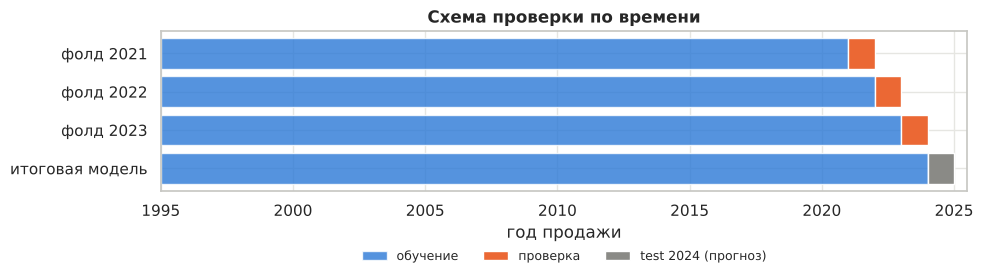

In [3]:
folds = rd('ml_folds.csv').set_index('год проверки')
show = folds.copy()
for c in show.columns:
    if '%' in c:
        show[c] = show[c].map('{:.1f}'.format)
    elif pd.api.types.is_numeric_dtype(show[c]):
        show[c] = show[c].map('{:,.0f}'.format)
display(show.T)

fig, ax = plt.subplots(figsize=(10, 3.2))
rows = [('фолд 2021', 2021), ('фолд 2022', 2022), ('фолд 2023', 2023), ('итоговая модель', 2024)]
for i, (name, y) in enumerate(rows):
    ax.barh(i, y - 1995, left=1995, color=BLUE, alpha=0.8, label='обучение' if i == 0 else None)
    ax.barh(i, 1, left=y, color=ORANGE, label='проверка' if i == 0 else None)
ax.barh(3, 1, left=2024, color=GRAY, label='test 2024 (прогноз)')
ax.set_yticks(range(len(rows)), [r[0] for r in rows])
ax.invert_yaxis()
ax.set_xlim(1995, 2025.5)
ax.set_xlabel('год продажи')
ax.set_title('Схема проверки по времени')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.3), ncol=3, fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

> **Что за график.** Каждая строка — один фолд: синим годы обучения, оранжевым год проверки. Нижняя строка — итоговая модель: обучается на всём train (1995–2023) и прогнозирует test 2024 (серым).
> **Что показывает.** Модель всегда проверяется на годе, которого не видела, как в реальной работе. В обучении от 186,8 тыс. до 232,9 тыс. продаж, в проверке от 19,8 тыс. (2021) до 33,4 тыс. (2023). Исключённых строк мало: дубликатов около 0,2%, подозрительных цен (оба правила) около 0,5% обучения. У 68% продаж года проверки есть прошлая продажа того же адреса, площадь пропущена у 4–6%.

## 3. Ориентиры без машинного обучения

Прежде чем учить модели, нужна планка: насколько хорошо можно угадать цену простым правилом. Любая ML-модель должна быть лучше.

- **0а. Медиана цены м² района × площадь.** Берём медиану цены за м² в том же outcode (почтовый район, например `SW1`) за прошлый год и умножаем на площадь объекта. Это то, как риелтор прикидывает цену «на глаз».
- **0б. Прошлая цена адреса.** Если адрес уже продавался, берём прошлую цену, увеличенную на рост цен в районе с тех пор (`prev_price_adj`); если нет — ориентир 0а.

In [4]:
BASE = ['0а. Медиана цены м² района × площадь', '0б. Прошлая цена адреса (иначе 0а)']
table(BASE)

,RMSE 2021,RMSE 2022,RMSE 2023,RMSE среднее,"MdAPE, %","в ±10%, %","в ±20%, %","MAE, тыс. £"
модель,,,,,,,,
0а. Медиана цены м² района × площадь,0.4226,0.4181,0.4081,0.4162,16.5,31.8,58.3,265
0б. Прошлая цена адреса (иначе 0а),0.4342,0.4344,0.4127,0.4271,16.7,32.2,57.3,268


**Что видно.** Простое правило 0а уже даёт RMSE_log 0,416: половина прогнозов ошибается меньше чем на 16,5%, в пределах ±20% попадают 58% продаж. Прошлая цена адреса (0б) неожиданно хуже (0,427): почти у половины адресов прошлая продажа была больше 10 лет назад, и «старая цена × рост района» хуже свежей медианы района. Дальше сравниваем все модели с ориентиром **0а = 0,416**.

## 4. Метод ближайших соседей (KNN)

### 4.1 Как работает и как подготовили признаки

**Идея KNN.** Чтобы оценить объект, находим k самых похожих на него продаж из обучения и берём среднее их log(цены за м²). Это почти то, что делает риелтор: «вот такие же квартиры рядом продавались по столько-то за метр». Модель `KNeighborsRegressor` из sklearn.

**Похожесть = расстояние между признаками**, поэтому важна подготовка (всё внутри `sklearn Pipeline`, обучается только на train-части фолда):
- **`StandardScaler`** приводит все признаки к одному масштабу (среднее 0, разброс 1). Без него признак в больших единицах (например, расстояние до центра в км от 0 до 25) заглушил бы признаки в маленьких (широта меняется в пределах 0,3 градуса);
- **пропуски** заполняются медианой (`SimpleImputer`), у строк без прошлой продажи её отличие от цен соседей = 0 («как у соседей»);
- **категории без one-hot.** One-hot превратил бы outcode в ~270 столбцов 0/1, и расстояние между объектами стало бы определяться в основном совпадением района, а не координатами и площадью. Район KNN и так видит через координаты; тип жилья и форму собственности кодируем двумя флагами 0/1 (`is_flat`, `is_freehold`);
- **log площади** вместо площади: разница 30 и 60 м² важнее, чем 300 и 330 м².

**Что подбираем** (по 2021–2022, каждый шаг берёт лучшее и передаёт дальше; новое значение принимаем, только если оно лучше текущего хотя бы на 0,001 — меньшая разница это шум):
1. **окно лет обучения** — сколько последних лет продаж брать в «соседи» (работа с данными). Цены 1995 года в разы ниже нынешних, и такие «соседи» только мешают;
2. **набор признаков** (feature engineering для KNN): только место → + объект (площадь, комнаты, тип) → + окружение (цены соседей за прошлый год, расстояния до центра и метро, IMD) → + прошлая продажа адреса;
3. **k и веса**: k от 5 до 100; `uniform` — все соседи равны, `distance` — ближние соседи весят больше;
4. **вес координат** — во сколько раз координаты важнее остальных признаков при поиске соседей.

KNN считается быстро (10–20 секунд на три фолда), поэтому обучаемся на полной train-части фолда (внутри выбранного окна лет), подвыборка не нужна.

In [5]:
kt = tun[tun['модель'] == 'KNN'].copy()
show = kt[['этап', 'настройки', 'RMSE_2021', 'RMSE_2022', 'RMSE_подбор', 'RMSE_2023', 'выбрано']]
display(show.style.format({c: '{:.4f}' for c in show.columns if c.startswith('RMSE')})
        .apply(lambda r: ['background-color: #e3f0e3' if r['выбрано'] else '' for _ in r], axis=1)
        .hide(axis='index'))

этап,настройки,RMSE_2021,RMSE_2022,RMSE_подбор,RMSE_2023,выбрано
1. окно лет обучения,признаки: место + объект; k = 5; веса: uniform; вес координат 1.0; окно 1 лет,0.4259,0.4213,0.4236,0.4079,False
1. окно лет обучения,признаки: место + объект; k = 5; веса: uniform; вес координат 1.0; окно 2 лет,0.4199,0.4204,0.4202,0.4030,False
1. окно лет обучения,признаки: место + объект; k = 5; веса: uniform; вес координат 1.0; окно 3 лет,0.4157,0.4166,0.4162,0.3995,False
1. окно лет обучения,признаки: место + объект; k = 5; веса: uniform; вес координат 1.0; окно 5 лет,0.4096,0.4155,0.4125,0.3973,True
1. окно лет обучения,признаки: место + объект; k = 5; веса: uniform; вес координат 1.0; окно 8 лет,0.4244,0.4181,0.4213,0.3940,False
1. окно лет обучения,признаки: место + объект; k = 5; веса: uniform; вес координат 1.0; окно 12 лет,0.4693,0.4590,0.4641,0.4113,False
1. окно лет обучения,признаки: место + объект; k = 5; веса: uniform; вес координат 1.0; окно 30 лет,0.9545,0.9272,0.9409,0.8325,False
2. набор признаков,признаки: место; k = 5; веса: uniform; вес координат 1.0; окно 5 лет,0.4134,0.4109,0.4122,0.3971,False
2. набор признаков,признаки: место + объект; k = 5; веса: uniform; вес координат 1.0; окно 5 лет,0.4096,0.4155,0.4125,0.3973,False
2. набор признаков,признаки: место + объект + окружение; k = 5; веса: uniform; вес координат 1.0; окно 5 лет,0.4077,0.4065,0.4071,0.3888,False


В таблице все проверенные настройки KNN; зелёным — выбранная на каждом этапе. `RMSE_подбор` — среднее по 2021–2022 (по нему выбираем), `RMSE_2023` — честная проверка.

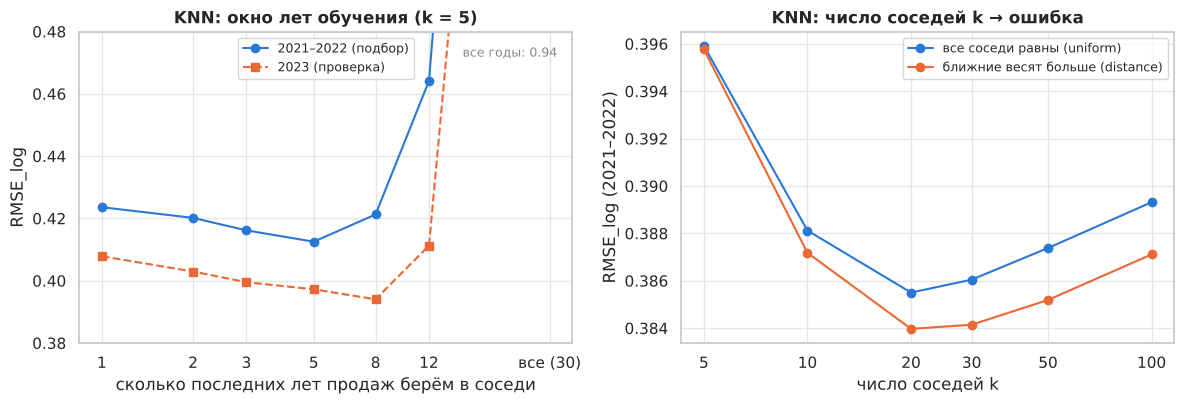

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
w = kt[kt['этап'].str.startswith('1.')]
ax = axes[0]
ax.plot(w['window'], w['RMSE_подбор'], 'o-', color=BLUE, label='2021–2022 (подбор)')
ax.plot(w['window'], w['RMSE_2023'], 's--', color=ORANGE, label='2023 (проверка)')
ax.set_xscale('log')
ax.set_xticks(w['window'], [('все (' + str(int(v)) + ')') if v >= 30 else str(int(v)) for v in w['window']])
ax.minorticks_off()
ax.set_xlabel('сколько последних лет продаж берём в соседи')
ax.set_ylabel('RMSE_log')
ax.set_title('KNN: окно лет обучения (k = 5)')
ax.set_ylim(0.38, 0.48)
ax.annotate(f"все годы: {w['RMSE_подбор'].iloc[-1]:.2f}", xy=(0.97, 0.95), xycoords='axes fraction',
            ha='right', va='top', fontsize=9, color=GRAY)
ax.legend(fontsize=9, loc='upper center')

kk = kt[kt['этап'].str.startswith('3.')]
ax = axes[1]
for wt, c, lab in (('uniform', BLUE, 'все соседи равны (uniform)'), ('distance', ORANGE, 'ближние весят больше (distance)')):
    d = kk[kk['weights'] == wt].sort_values('k')
    ax.plot(d['k'], d['RMSE_подбор'], 'o-', color=c, label=lab)
ax.set_xscale('log')
ax.set_xticks([5, 10, 20, 30, 50, 100], ['5', '10', '20', '30', '50', '100'])
ax.minorticks_off()
ax.set_xlabel('число соседей k')
ax.set_ylabel('RMSE_log (2021–2022)')
ax.set_title('KNN: число соседей k → ошибка')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

> **Что за график.** Слева: ошибка KNN в зависимости от того, сколько последних лет продаж берём в «соседи» (синим — среднее 2021–2022, по нему выбираем; оранжевым — 2023). Справа: ошибка в зависимости от числа соседей k для двух способов усреднения (на лучшем наборе признаков).
> **Что показывает.** Если брать соседей из всех лет с 1995-го, KNN ошибается очень сильно (RMSE_log 0,94): самые похожие по координатам и площади продажи часто оказываются 20-летней давности по старым ценам. На 2021–2022 лучше всего окно 5 лет (0,413), при 8 и 12 годах ошибка снова растёт; в 2023 году окно 8 лет чуть лучше, но выбираем только по 2021–2022. По k ошибка сначала быстро падает (5 соседей — шумное среднее), минимум около k = 20–30, затем медленно растёт (100 соседей уже захватывают другие районы). Взвешивание по расстоянию (`distance`) немного лучше при любом k.

In [7]:
KNN = models_like('KNN')
table(KNN)

,RMSE 2021,RMSE 2022,RMSE 2023,RMSE среднее,"MdAPE, %","в ±10%, %","в ±20%, %","MAE, тыс. £"
модель,,,,,,,,
"KNN: начальный (k = 5, место + объект, все годы)",0.9545,0.9272,0.8325,0.9047,53.6,4.0,8.7,511
KNN: + окно лет,0.4096,0.4155,0.3973,0.4074,16.1,32.8,59.4,263
KNN: + набор признаков,0.3979,0.3940,0.3697,0.3872,14.2,37.1,64.5,240
KNN: + подбор k и весов,0.3841,0.3838,0.3572,0.3750,13.4,38.8,67.2,233
KNN: + вес координат (итог),0.3841,0.3838,0.3572,0.3750,13.4,38.8,67.2,233


**Что видно.** Путь KNN от начальной настройки к итоговой (каждая строка добавляет один шаг, средние по трём годам):
- начальная версия (k = 5, все годы) хуже простого ориентира в два раза (0,905) — из-за старых цен;
- окно последних 5 лет — главный шаг работы с данными: 0,407, уже лучше ориентира 0а (0,416);
- полный набор признаков (место, объект, окружение, прошлая продажа) — 0,387;
- подбор k = 20 и весов `distance` — **0,375**;
- вес координат (×0,5, ×2, ×3) почти ничего не меняет (разница меньше 0,001), поэтому оставили 1.

Подбор не переобучен: выбор делался по 2021–2022, а в 2023 году ошибка тоже упала (с 0,397 после окна лет до 0,357).

## 5. Линейные модели: LinearRegression, Ridge, Lasso

### 5.1 Как устроены

Линейная модель считает прогноз как сумму: `log(цена за м²) = b0 + b1·признак1 + b2·признак2 + …`. Коэффициенты `b` подбираются так, чтобы ошибка на обучении была минимальной. Плюс линейной модели — **её коэффициенты читаются**: видно, какой фактор и насколько повышает или понижает цену (это вторая половина темы проекта — «оценка влияния факторов»).

- **LinearRegression** — обычный метод наименьших квадратов, без ограничений.
- **Ridge** — то же, но штрафует большие коэффициенты (регуляризация L2, сила штрафа `alpha`). Помогает, когда признаков много и они похожи друг на друга.
- **Lasso** — штраф L1: часть коэффициентов становится ровно нулём, то есть модель сама отбрасывает лишние признаки.

**Pipeline (sklearn)** — одинаковый для всех трёх, всё обучается только на train-части фолда:
- числа: заполнение пропусков медианой (`SimpleImputer`) → `StandardScaler` (нужен, чтобы штраф Ridge/Lasso действовал на все признаки одинаково и коэффициенты можно было сравнивать);
- флаги 0/1 — как есть;
- категории (тип жилья, форма собственности, энергокласс, outcode, borough) — `OneHotEncoder`: каждая категория становится столбцом 0/1; категории, которые встречаются меньше 20 раз, объединяются в одну, новые категории в проверке игнорируются.

### 5.2 Feature engineering для линейной модели

Начинаем с исходных столбцов (площадь, комнаты, координаты, месяц и год продажи + категории) и добавляем изменения по одному. Изменение остаётся, если помогает (лучше в среднем и не меньше чем в 2 годах из 3), иначе откатываем (`не взяли`). Модель на этом этапе — Ridge с `alpha = 1`.

In [8]:
LIN = ['LinearRegression: исходные столбцы', 'Ridge (alpha = 1): исходные столбцы'] + models_like('Ridge, шаг')
table(LIN)

,RMSE 2021,RMSE 2022,RMSE 2023,RMSE среднее,"MdAPE, %","в ±10%, %","в ±20%, %","MAE, тыс. £"
модель,,,,,,,,
LinearRegression: исходные столбцы,0.4949,0.4764,0.4812,0.4842,28.2,19.9,37.6,327
Ridge (alpha = 1): исходные столбцы,0.4949,0.4764,0.4813,0.4842,28.2,19.9,37.6,327
"Ridge, шаг 1: площадь -> log площади",0.4914,0.4732,0.4786,0.4811,28.0,20.1,37.8,321
"Ridge, шаг 2: + признаки чекпойнта 2 (прошлая продажа, расстояния, транспорт, соседи, IMD, borough)",0.4391,0.4204,0.4174,0.4256,21.7,25.4,47.0,273
"Ridge, шаг 3: без года продажи (уровень цен - через цены соседей прошлого года)",0.3919,0.3940,0.3678,0.3846,14.5,35.9,64.3,244
"Ridge, шаг 4: + флаги пропусков",0.3908,0.3920,0.3672,0.3833,14.5,35.9,64.2,243
"Ridge, шаг 5: + квадраты и взаимодействия",0.3805,0.3784,0.3592,0.3727,13.2,39.7,67.7,228
"Ridge, шаг 6: + флаг «адрес на несколько квартир» (по прошлому) (не взяли)",0.3805,0.3784,0.3593,0.3727,13.2,39.7,67.7,228
"Ridge, шаг 7: обучение только на последних 10 годах",0.3777,0.3739,0.3560,0.3692,12.7,40.7,69.2,224


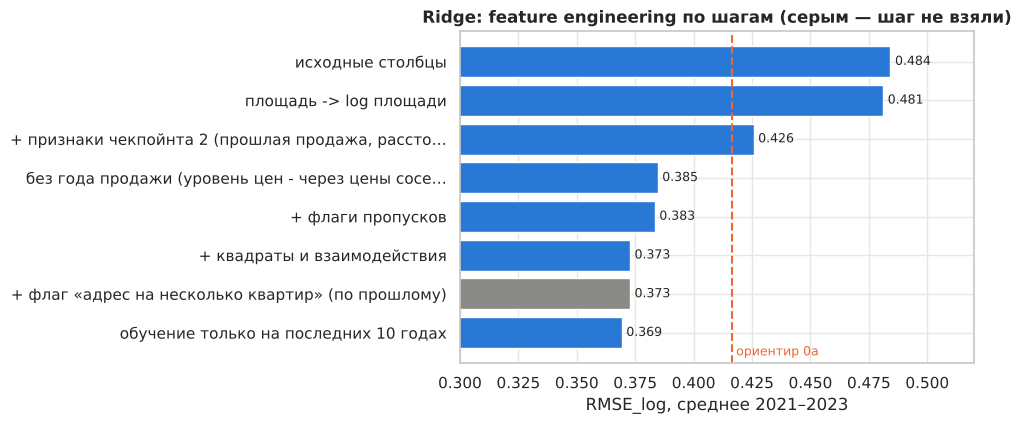

In [9]:
lin_steps = res[(res['модель'].isin(LIN[1:])) & (res['проверка'] == 'все')].groupby('модель', sort=False)['RMSE_log'].mean()
lab = ['исходные столбцы'] + [m.split(': ', 1)[1].replace(' (не взяли)', '') for m in lin_steps.index[1:]]
lab = [l if len(l) < 50 else l[:47] + '…' for l in lab]
taken = ['не взяли' not in m for m in lin_steps.index]
fig, ax = plt.subplots(figsize=(10, 4.4))
y = np.arange(len(lin_steps))
ax.barh(y, lin_steps.values, color=[BLUE if t else GRAY for t in taken])
for i, v in enumerate(lin_steps.values):
    ax.text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=9)
ax.axvline(rmse(BASE[0]), color=ORANGE, ls='--', lw=1.5)
ax.text(rmse(BASE[0]) + 0.002, len(y) - 0.5, 'ориентир 0а', color=ORANGE, fontsize=9, va='center')
ax.set_yticks(y, lab)
ax.invert_yaxis()
ax.set_xlim(0.30, 0.52)
ax.set_xlabel('RMSE_log, среднее 2021–2023')
ax.set_title('Ridge: feature engineering по шагам (серым — шаг не взяли)')
plt.tight_layout()
plt.show()

> **Что за график.** Ошибка Ridge после каждого шага feature engineering (сверху вниз — по порядку). Синим — шаги, которые оставили, серым — не взятый шаг; оранжевая линия — ориентир 0а.
> **Что показывает.** На исходных столбцах линейная модель хуже простого ориентира (0,484 против 0,416). Самые сильные шаги:
> - **+ признаки чекпойнта 2** (цены соседей за прошлый год, прошлая продажа, расстояния, транспорт, IMD, borough): 0,481 → 0,426;
> - **убрать год продажи**: 0,426 → 0,385. Линейная модель продолжает тренд по годам прямой линией, а цены в Лондоне росли неравномерно (в 2021–2023 почти стояли), поэтому прямая промахивается. Уровень цен модель и так знает из цен соседей за прошлый год;
> - **квадраты и взаимодействия** (квадрат log площади, log площади × «квартира», квадрат расстояния до центра, цены соседей × «квартира»): 0,383 → 0,373. Линейная модель сама умеет только прямые линии, а эти признаки дают ей изгиб и разный наклон для квартир и домов;
> - **обучение только на последних 10 годах**: 0,373 → 0,369. Связь цены с признаками со временем меняется, и старые годы мешают.
>
> log площади и флаги пропусков дали небольшой плюс; флаг «адрес на несколько квартир» не помог.

### 5.3 Подбор alpha и сравнение LinearRegression, Ridge, Lasso

На итоговом наборе признаков подбираем силу регуляризации `alpha` по 2021–2022.

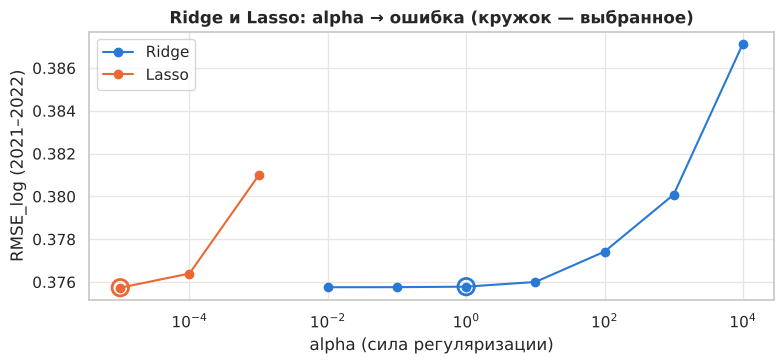

модель,настройки,RMSE_2021,RMSE_2022,RMSE_2023,RMSE_подбор,выбрано,ненулевых коэффициентов (2023)
Ridge,alpha = 0.01,0.3777,0.3739,0.3560,0.3758,False,
Ridge,alpha = 0.1,0.3776,0.3739,0.3560,0.3758,False,
Ridge,alpha = 1,0.3777,0.3739,0.3560,0.3758,True,
Ridge,alpha = 10,0.3778,0.3742,0.3562,0.3760,False,
Ridge,alpha = 100,0.3787,0.3761,0.3572,0.3774,False,
Ridge,alpha = 1000,0.3805,0.3797,0.3595,0.3801,False,
Ridge,alpha = 10000,0.3860,0.3883,0.3629,0.3871,False,
Lasso,alpha = 1e-05,0.3776,0.3739,0.3560,0.3757,True,215 из 238
Lasso,alpha = 0.0001,0.3779,0.3749,0.3564,0.3764,False,
Lasso,alpha = 0.001,0.3814,0.3805,0.3612,0.3810,False,


In [10]:
rt = tun[tun['модель'].isin(['Ridge', 'Lasso'])]
fig, ax = plt.subplots(figsize=(8, 3.8))
for mname, c in (('Ridge', BLUE), ('Lasso', ORANGE)):
    d = rt[rt['модель'] == mname].sort_values('alpha')
    ax.plot(d['alpha'], d['RMSE_подбор'], 'o-', color=c, label=mname)
    s = d[d['выбрано']]
    ax.scatter(s['alpha'], s['RMSE_подбор'], s=140, facecolors='none', edgecolors=c, linewidths=2)
ax.set_xscale('log')
ax.set_xlabel('alpha (сила регуляризации)')
ax.set_ylabel('RMSE_log (2021–2022)')
ax.set_title('Ridge и Lasso: alpha → ошибка (кружок — выбранное)')
ax.legend()
plt.tight_layout()
plt.show()
display(rt[['модель', 'настройки', 'RMSE_2021', 'RMSE_2022', 'RMSE_2023', 'RMSE_подбор', 'выбрано',
            'ненулевых коэффициентов (2023)']].fillna('').style.format(
    {c: '{:.4f}' for c in ['RMSE_2021', 'RMSE_2022', 'RMSE_2023', 'RMSE_подбор']}).hide(axis='index'))

> **Что за график.** Ошибка Ridge (синим) и Lasso (оранжевым) при разной силе регуляризации `alpha` (шкала логарифмическая); кружком отмечено выбранное значение.
> **Что показывает.** У Ridge ошибка почти не меняется при `alpha` от 0,01 до 10 и растёт только при сильном штрафе (1000 и больше). Это нормально: обучающих строк больше 100 тысяч, а столбцов после one-hot около 240, поэтому переобучиться линейной модели трудно, и регуляризация почти не нужна. При равной ошибке выбираем большее `alpha` (более «осторожную» модель). Lasso при заметном штрафе (`alpha` = 0,001) начинает выбрасывать полезные признаки и ухудшается; при маленьком штрафе (`alpha` = 0,00001) он совпадает с Ridge и обнуляет только 23 коэффициента из 238.

In [11]:
LIN_FINAL = [m for m in res['модель'].drop_duplicates()
             if m.startswith(('LinearRegression', 'Ridge:', 'Lasso'))]
table(LIN_FINAL)

,RMSE 2021,RMSE 2022,RMSE 2023,RMSE среднее,"MdAPE, %","в ±10%, %","в ±20%, %","MAE, тыс. £"
модель,,,,,,,,
LinearRegression: исходные столбцы,0.4949,0.4764,0.4812,0.4842,28.2,19.9,37.6,327
"Ridge: признаки + подбор alpha (итог, alpha = 1)",0.3777,0.3739,0.3560,0.3692,12.7,40.7,69.2,224
LinearRegression: итоговые признаки,0.3777,0.3739,0.3560,0.3692,12.7,40.7,69.3,224
Lasso: итоговые признаки (alpha = 1e-05),0.3776,0.3739,0.3560,0.3692,12.7,40.8,69.3,224


**Что видно.** На хороших признаках LinearRegression, Ridge и Lasso дают одно и то же: **0,369** (лучше ориентира 0а на 0,047 и немного лучше KNN — 0,375). Регуляризация здесь не главное; главное — признаки: от исходных столбцов (0,484) до итогового набора (0,369) ошибка упала на четверть.

### 5.4 Влияние факторов: коэффициенты Ridge

Чтобы коэффициенты можно было читать по одному, берём Ridge на итоговом наборе **без квадратов и взаимодействий** (с ними, например, площадь входит в три признака сразу, и отдельный коэффициент теряет смысл). Модель обучена на годах до 2022, проверка — 2023. Для чисел показано, насколько меняется цена за м², если признак вырастет на одно стандартное отклонение (типичный разброс), при прочих равных; для флагов — разница «да» против «нет».

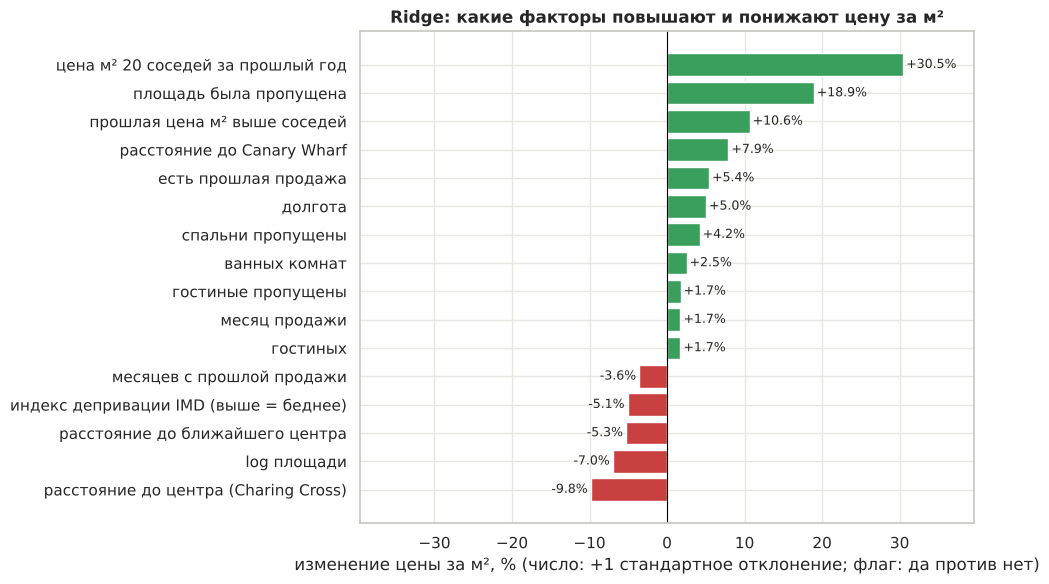

In [12]:
imp = rd('ml_importance.csv')
co = imp[imp['источник'].str.startswith('Ridge')].copy()
NAMES = {'log_area': 'log площади', 'knn20_prev_med_logppsm': 'цена м² 20 соседей за прошлый год',
         'dist_charing_cross_km': 'расстояние до центра (Charing Cross)', 'dist_canary_wharf_km': 'расстояние до Canary Wharf',
         'dist_nearest_centre_km': 'расстояние до ближайшего центра', 'dist_subcentre_km': 'расстояние до районного центра',
         'imd_score': 'индекс депривации IMD (выше = беднее)', 'prev_rel_knn': 'прошлая цена м² выше соседей',
         'has_prev': 'есть прошлая продажа', 'prev_sale_gap_months': 'месяцев с прошлой продажи',
         'bathrooms_filled': 'ванных комнат', 'bedrooms_filled': 'спален', 'livingRooms_filled': 'гостиных',
         'floorAreaSqM_missing': 'площадь была пропущена', 'bedrooms_missing': 'спальни пропущены',
         'bathrooms_missing': 'ванные пропущены', 'livingRooms_missing': 'гостиные пропущены',
         'crime_decile': 'дециль преступности IMD', 'living_env_decile': 'дециль среды IMD',
         'dist_station_km': 'расстояние до станции', 'dist_tube_km': 'расстояние до метро',
         'n_addr_500m': 'адресов в радиусе 500 м', 'latitude': 'широта', 'longitude': 'долгота', 'sale_month': 'месяц продажи'}
num = co[co['группа'].isin(['num', 'flag'])].copy()
num['название'] = num['признак'].map(NAMES).fillna(num['признак'])
num = num.reindex(num['эффект_%'].abs().sort_values(ascending=False).index).head(16).sort_values('эффект_%')
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(num['название'], num['эффект_%'], color=[GREEN if v > 0 else RED for v in num['эффект_%']])
for i, v in enumerate(num['эффект_%']):
    ax.text(v + (0.4 if v > 0 else -0.4), i, f'{v:+.1f}%', va='center', ha='left' if v > 0 else 'right', fontsize=9)
ax.axvline(0, color='black', lw=0.8)
lim = num['эффект_%'].abs().max() * 1.3
ax.set_xlim(-lim, lim)
ax.set_xlabel('изменение цены за м², % (число: +1 стандартное отклонение; флаг: да против нет)')
ax.set_title('Ridge: какие факторы повышают и понижают цену за м²')
plt.tight_layout()
plt.show()

> **Что за график.** 16 числовых признаков и флагов с самым большим влиянием в линейной модели. Зелёным — повышают цену за м², красным — понижают. Для числа: эффект от роста признака на одно стандартное отклонение (столбец `стд` в `reports/ml_importance.csv` — его значение в исходных единицах), для флага — «да» против «нет».
> **Что показывает.**
> - Сильнее всего цену за м² определяет **уровень цен соседей за прошлый год** (+31% на одно стандартное отклонение): чем дороже метр рядом, тем дороже метр у объекта.
> - **«Площадь была пропущена»** (+19%) — это не свойство жилья, а след заполнения: у таких объектов площадь заполнена медианой, а настоящая обычно меньше, поэтому цена, делённая на заполненную площадь, кажется выше. Модель учится это поправлять.
> - **Прошлая продажа:** если адрес раньше продавался дороже соседей, он и сейчас дороже (+11%); чем дольше назад была прошлая продажа, тем слабее эта связь (−4%).
> - **Расстояние до центра** (−10%), **до ближайшего центра района** (−5%), **индекс депривации** (−5%): дальше от центра и в более бедном районе метр дешевле.
> - **Площадь со знаком минус** (−7%): при прочих равных у больших объектов метр дешевле (гипотеза из раздела 9).
> - Положительный знак у расстояния до Canary Wharf и долготы не значит «чем дальше, тем лучше»: расстояния до разных центров сильно связаны между собой, и коэффициенты делят влияние между ними.
>
> Это связь в данных при прочих равных, а не доказанная причина.

In [13]:
cat = co[co['группа'] == 'cat'].copy()
cat['столбец'] = cat['признак'].str.rsplit('_', n=1).str[0]
cat['значение категории'] = cat['признак'].str.rsplit('_', n=1).str[1]
cat = cat[cat['столбец'].isin(['pt_group_filled', 'tenure_filled'])]
cat['столбец'] = cat['столбец'].map({'pt_group_filled': 'тип жилья', 'tenure_filled': 'форма собственности'})
cat = cat[['столбец', 'значение категории', 'эффект_%']].sort_values(['столбец', 'эффект_%'])
display(cat.style.format({'эффект_%': '{:+.1f}'}).hide(axis='index'))

столбец,значение категории,эффект_%
тип жилья,Unknown,-33.1
тип жилья,Flat,-5.9
тип жилья,End terrace,+5.9
тип жилья,Terraced,+7.4
тип жилья,Semi-detached,+8.8
тип жилья,Bungalow,+10.4
тип жилья,Detached,+16.3
форма собственности,Shared,-11.7
форма собственности,Unknown,-0.8
форма собственности,Feudal,+3.4


**Что видно.** Для категорий one-hot даёт коэффициент каждой категории; разницу между двумя категориями читаем как разницу их эффектов. При одинаковых площади, районе и прочем квартира (`Flat`, −6%) дешевле за м², чем дома (от +6% у `End terrace` до +16% у `Detached`): квартира дешевле отдельного дома за м² примерно на 19% (0,941 / 1,163 ≈ 0,81). Форма собственности `Freehold` (дом и земля в собственности, +6%) немного дороже `Leasehold` (долгосрочная аренда, +4%), а `Shared` (долевая собственность) дешевле (−12%). Эффекты outcode и borough (их сотни) лежат в `reports/ml_importance.csv`.

## 6. Градиентный бустинг LightGBM (для сравнения)

По требованиям чекпойнта обязательны простые модели (KNN, линейные). Градиентный бустинг — более сильная модель, которую берём как ориентир «сколько ещё можно выиграть» и как основу будущего сервиса. Поэтому раздел короткий.

**Как работает.** Модель строит сотни небольших деревьев решений; каждое следующее дерево исправляет ошибки предыдущих. Деревья сами находят нелинейности и взаимодействия признаков, им не нужны масштабирование и one-hot, а пропуски (`NaN`) они обрабатывают сами. Признаки: исходные столбцы (с пропусками) + 15 признаков чекпойнта 2.

### 6.1 Подбор гиперпараметров

Случайный поиск: 25 случайных комбинаций из сетки (число деревьев, скорость обучения, число листьев в дереве, минимум строк в листе, доля строк и признаков для каждого дерева, L2-регуляризация). Каждая комбинация обучается на фолдах 2021 и 2022, выбираем лучшую по их среднему, затем проверяем её на 2023.

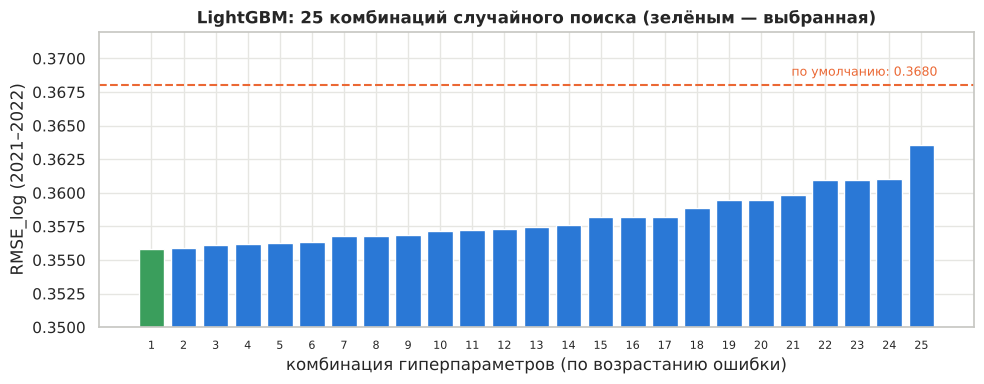

,n_estimators,learning_rate,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,RMSE_подбор,секунд
0,800.000000,0.03,255.000000,10.000000,1.00,0.5,5,0.3558,29
1,500.000000,0.03,255.000000,100.000000,0.85,0.7,5,0.3559,26
2,800.000000,0.05,127.000000,50.000000,0.70,0.5,0,0.3561,21
3,1200.000000,0.08,63.000000,100.000000,0.70,0.5,5,0.3562,23
4,1200.000000,0.05,63.000000,100.000000,0.85,0.5,1,0.3563,24


In [14]:
lt = tun[tun['модель'] == 'LightGBM'].copy()
srch = lt[lt['этап'] == 'случайный поиск'].sort_values('RMSE_подбор').reset_index(drop=True)
dflt = lt[lt['этап'] == 'по умолчанию'].iloc[0]
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(range(len(srch)), srch['RMSE_подбор'], color=[GREEN if s else BLUE for s in srch['выбрано']])
ax.axhline(dflt['RMSE_подбор'], color=ORANGE, ls='--', lw=1.5)
ax.text(len(srch) - 0.5, dflt['RMSE_подбор'] + 0.0007, f"по умолчанию: {dflt['RMSE_подбор']:.4f}", color=ORANGE,
        ha='right', fontsize=9)
ax.set_ylim(0.35, 0.372)
ax.set_xticks(range(len(srch)), [str(i + 1) for i in range(len(srch))], fontsize=8)
ax.set_xlabel('комбинация гиперпараметров (по возрастанию ошибки)')
ax.set_ylabel('RMSE_log (2021–2022)')
ax.set_title('LightGBM: 25 комбинаций случайного поиска (зелёным — выбранная)')
plt.tight_layout()
plt.show()
cols = ['n_estimators', 'learning_rate', 'num_leaves', 'min_child_samples', 'subsample', 'colsample_bytree', 'reg_lambda',
        'RMSE_подбор', 'секунд']
display(srch[cols].head(5).style.format({'RMSE_подбор': '{:.4f}', 'learning_rate': '{:.2f}', 'subsample': '{:.2f}',
                                         'colsample_bytree': '{:.1f}', 'reg_lambda': '{:.0f}', 'секунд': '{:.0f}'}))

> **Что за график.** Ошибка каждой из 25 проверенных комбинаций на 2021–2022 (по возрастанию); оранжевая линия — LightGBM с настройками по умолчанию (100 деревьев, `learning_rate` 0,1, 31 лист). Под графиком пять лучших комбинаций.
> **Что показывает.** Все комбинации лучше настроек по умолчанию: модели по умолчанию просто не хватает деревьев. Лучше всего работают деревья с большим числом листьев (63–255) и частью признаков на каждое дерево (`colsample_bytree` 0,5). Разница между пятью лучшими комбинациями меньше 0,001, поэтому точный выбор не критичен.

In [15]:
LGB = ['LightGBM: по умолчанию', 'LightGBM: подбор гиперпараметров']
table(LGB)

,RMSE 2021,RMSE 2022,RMSE 2023,RMSE среднее,"MdAPE, %","в ±10%, %","в ±20%, %","MAE, тыс. £"
модель,,,,,,,,
LightGBM: по умолчанию,0.3705,0.3655,0.3462,0.3607,12.2,42.1,70.8,217
LightGBM: подбор гиперпараметров,0.3599,0.3518,0.3301,0.3473,11.1,45.6,74.3,202


**Что видно.** Подбор улучшил LightGBM с 0,361 до **0,347**, MdAPE с 12,2% до 11,1%. **Подбор не переобучен:** комбинация выбиралась только по 2021–2022, а на 2023 годе (его при выборе не видели) ошибка тоже упала — с 0,346 до 0,330.

### 6.2 Работа с данными и признаками

Каждое изменение проверяется отдельно, относительно модели после подбора (0,347). Признаки оставляем по общему правилу (лучше в среднем и в 2 годах из 3). Правила отбора строк приняты заранее (обучение без дубликатов и подозрительных цен), опыты с ними показывают, сколько это стоит.

In [16]:
EXP = models_like('LightGBM, опыт')
ref = res[(res['модель'] == LGB[1]) & (res['проверка'] == 'все')].set_index('год')['RMSE_log']
rows = []
for m in EXP:
    r = res[(res['модель'] == m) & (res['проверка'] == 'все')].set_index('год')['RMSE_log']
    rc = res[(res['модель'] == m) & (res['проверка'] != 'все')]
    rows.append({'опыт': m.replace('LightGBM, опыт: ', ''),
                 **{f'Δ {y}': r[y] - ref[y] for y in YEARS}, 'Δ среднее': r.mean() - ref.mean(),
                 'RMSE среднее': r.mean(), 'RMSE без подозр. цен': rc['RMSE_log'].mean(),
                 'MdAPE, %': res[(res['модель'] == m) & (res['проверка'] == 'все')]['MdAPE_%'].mean()})
ex = pd.DataFrame(rows)
rr = res[(res['модель'] == LGB[1])]
print(f"после подбора: RMSE {rr[rr['проверка'] == 'все']['RMSE_log'].mean():.4f}, без подозрительных цен "
      f"{rr[rr['проверка'] != 'все']['RMSE_log'].mean():.4f}, MdAPE {rr[rr['проверка'] == 'все']['MdAPE_%'].mean():.2f}%")
print('приняты изменения:', best['lgb']['accepted'])
display(ex.style.format({c: '{:+.4f}' for c in ex.columns if c.startswith('Δ')} |
                        {'RMSE среднее': '{:.4f}', 'RMSE без подозр. цен': '{:.4f}', 'MdAPE, %': '{:.2f}'})
        .background_gradient(subset=['Δ среднее'], cmap='RdYlGn_r', vmin=-0.004, vmax=0.004).hide(axis='index'))

после подбора: RMSE 0.3473, без подозрительных цен 0.2795, MdAPE 11.14%
приняты изменения: ['+ цена м² прошлой продажи (log_prev_ppsm_adj, prev_rel_knn)', '+ флаг «адрес на несколько квартир» (по прошлому)']


опыт,Δ 2021,Δ 2022,Δ 2023,Δ среднее,RMSE среднее,RMSE без подозр. цен,"MdAPE, %"
строки: обучение на всех строках (с дубликатами и подозрительными ценами),-0.0042,-0.0045,-0.0016,-0.0034,0.3438,0.2821,11.43
строки: без правила price_suspect_noarea (исключаем только price_suspect),-0.0030,-0.0043,-0.0017,-0.0030,0.3443,0.2793,11.15
пропуски: заполненные *_filled вместо пропусков,+0.0010,+0.0034,+0.0006,+0.0017,0.3489,0.2815,11.16
"+ цена м² прошлой продажи (log_prev_ppsm_adj, prev_rel_knn)",-0.0016,-0.0005,+0.0002,-0.0006,0.3466,0.2791,11.12
+ флаг «адрес на несколько квартир» (по прошлому),-0.0012,-0.0006,+0.0004,-0.0005,0.3468,0.2791,11.08
+ флаги пропусков и подозрительной площади,+0.0005,-0.0010,+0.0000,-0.0002,0.3471,0.2792,11.12


**Что видно** (Δ < 0 — ошибка уменьшилась):
- **+ цена м² прошлой продажи** (прошлая цена с поправкой, делённая на площадь, и её отличие от цен соседей) и **+ флаг «адрес на несколько квартир»** (только по прошлым продажам, без взгляда в будущее) — небольшой плюс (−0,0006 и −0,0005, лучше в 2021 и 2022 годах, в 2023 почти без изменений). Взяли оба;
- флаги пропусков и подозрительной площади — около нуля, не взяли;
- **заполненные `*_filled` вместо пропусков хуже** (+0,0017, хуже во всех годах): деревья лучше сами разбираются с пропусками, а заполненное медианой значение выглядит как настоящее;
- **отбор строк — важная оговорка.** Обучение на всех строках (с дубликатами и подозрительными ценами) даёт *лучшую* ключевую метрику (−0,0034, лучше во всех трёх годах), но на продажах без подозрительных цен ошибка хуже (0,282 против 0,280), и типичная ошибка MdAPE хуже (11,4% против 11,1%). То есть модель, обученная на ошибочных ценах, лучше «угадывает» ошибочные цены в проверке, но хуже оценивает обычное жильё. Для сервиса оценки важнее обычное жильё, поэтому оставили исключение. Отдельно правило `price_suspect_noarea` по ключевой метрике не помогает (без него −0,003), а на «чистых» строках и по MdAPE разницы нет: из 200–270 помеченных цен в обучении часть, видимо, настоящие продажи целых домов. Правило оставили как принятое решение; это вопрос для обсуждения с куратором.

Итоговая модель — подбор + два принятых признака.

In [17]:
LGB_ALL = LGB + ['LightGBM: подбор + признаки (итог)', 'справка: итоговый LightGBM с целью log(цены)']
table(LGB_ALL)

,RMSE 2021,RMSE 2022,RMSE 2023,RMSE среднее,"MdAPE, %","в ±10%, %","в ±20%, %","MAE, тыс. £"
модель,,,,,,,,
LightGBM: по умолчанию,0.3705,0.3655,0.3462,0.3607,12.2,42.1,70.8,217
LightGBM: подбор гиперпараметров,0.3599,0.3518,0.3301,0.3473,11.1,45.6,74.3,202
LightGBM: подбор + признаки (итог),0.3592,0.3516,0.3296,0.3468,11.1,45.7,74.3,201
справка: итоговый LightGBM с целью log(цены),0.3588,0.3519,0.3300,0.3469,11.1,45.9,74.2,202


**Что видно.** Два новых признака вместе дают 0,3468 против 0,3473 после подбора (лучше во всех трёх годах, но совсем немного). Главный выигрыш у бустинга дал подбор гиперпараметров (−0,014), признаки — ещё −0,0005. Та же модель с целью log(цены) вместо log(цены за м²) даёт практически то же (0,3469): выбор цели «цена за м²» качество не ухудшает.

## 7. Итоговое сравнение моделей

In [18]:
FINAL = res.loc[res['итог'], 'модель'].drop_duplicates().tolist()
def short_name(m):
    if m.startswith('KNN: + вес'):
        return 'KNN: подбор + признаки'
    return m.split(' (итог')[0].split(' (alpha')[0]
SHORT = {m: short_name(m) for m in FINAL}
display(table(FINAL, short=SHORT))
print('Без подозрительных цен в проверке:')
display(table(FINAL, subset='без подозрительных цен', short=SHORT))

,RMSE 2021,RMSE 2022,RMSE 2023,RMSE среднее,"MdAPE, %","в ±10%, %","в ±20%, %","MAE, тыс. £"
0а. Медиана цены м² района × площадь,0.4226,0.4181,0.4081,0.4162,16.5,31.8,58.3,265
0б. Прошлая цена адреса (иначе 0а),0.4342,0.4344,0.4127,0.4271,16.7,32.2,57.3,268
"KNN: начальный (k = 5, место + объект, все годы)",0.9545,0.9272,0.8325,0.9047,53.6,4.0,8.7,511
KNN: подбор + признаки,0.3841,0.3838,0.3572,0.3750,13.4,38.8,67.2,233
LinearRegression: исходные столбцы,0.4949,0.4764,0.4812,0.4842,28.2,19.9,37.6,327
Ridge: признаки + подбор alpha,0.3777,0.3739,0.3560,0.3692,12.7,40.7,69.2,224
Lasso: итоговые признаки,0.3776,0.3739,0.3560,0.3692,12.7,40.8,69.3,224
LightGBM: по умолчанию,0.3705,0.3655,0.3462,0.3607,12.2,42.1,70.8,217
LightGBM: подбор гиперпараметров,0.3599,0.3518,0.3301,0.3473,11.1,45.6,74.3,202
LightGBM: подбор + признаки,0.3592,0.3516,0.3296,0.3468,11.1,45.7,74.3,201


Без подозрительных цен в проверке:


,RMSE 2021,RMSE 2022,RMSE 2023,RMSE среднее,"MdAPE, %","в ±10%, %","в ±20%, %","MAE, тыс. £"
0а. Медиана цены м² района × площадь,0.3551,0.3529,0.3594,0.3558,16.4,32.0,58.7,218
0б. Прошлая цена адреса (иначе 0а),0.3694,0.3679,0.3701,0.3691,16.6,32.3,57.6,223
"KNN: начальный (k = 5, место + объект, все годы)",0.9288,0.9015,0.8130,0.8811,53.5,4.0,8.7,464
KNN: подбор + признаки,0.3095,0.3152,0.3079,0.3109,13.3,39.0,67.6,187
LinearRegression: исходные столбцы,0.4406,0.4225,0.4423,0.4351,28.0,20.0,37.8,281
Ridge: признаки + подбор alpha,0.3028,0.3019,0.3063,0.3037,12.6,41.0,69.6,178
Lasso: итоговые признаки,0.3027,0.3019,0.3062,0.3036,12.6,41.0,69.7,178
LightGBM: по умолчанию,0.2945,0.2929,0.2958,0.2944,12.1,42.4,71.3,172
LightGBM: подбор гиперпараметров,0.2819,0.2781,0.2786,0.2795,11.1,45.9,74.7,158
LightGBM: подбор + признаки,0.2813,0.2785,0.2783,0.2794,11.0,45.9,74.7,157


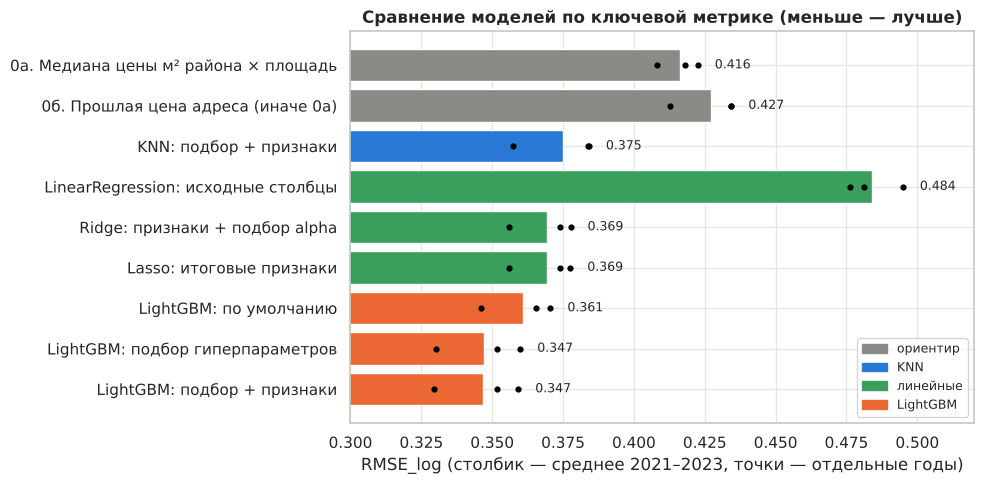

In [19]:
FAM = {'ориентир': GRAY, 'KNN': BLUE, 'линейные': GREEN, 'LightGBM': ORANGE}
fr = res[res['модель'].isin(FINAL) & (res['проверка'] == 'все')]
mean = fr.groupby('модель', sort=False).agg(RMSE=('RMSE_log', 'mean'), раздел=('раздел', 'first')).loc[FINAL]
mean = mean[mean['RMSE'] < 0.6]  # начальный KNN (0,90) не помещается на шкалу, он есть в таблице выше
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(mean))
ax.barh(y, mean['RMSE'], color=[FAM[s] for s in mean['раздел']])
for i, (m, r) in enumerate(mean.iterrows()):
    yr = fr[fr['модель'] == m].set_index('год')['RMSE_log']
    ax.scatter(yr.values, [i] * 3, color='black', s=12, zorder=3)
    ax.text(max(r['RMSE'], yr.max()) + 0.006, i, f"{r['RMSE']:.3f}", va='center', fontsize=9)
ax.set_yticks(y, [SHORT[m] for m in mean.index])
ax.invert_yaxis()
ax.set_xlim(0.30, 0.52)
ax.set_xlabel('RMSE_log (столбик — среднее 2021–2023, точки — отдельные годы)')
ax.set_title('Сравнение моделей по ключевой метрике (меньше — лучше)')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in FAM.values()]
ax.legend(handles, FAM.keys(), loc='lower right', fontsize=9)
plt.tight_layout()
plt.show()

> **Что за график.** Для каждой модели столбик — средняя ключевая метрика RMSE_log за 2021–2023, чёрные точки — отдельные годы. Цвет — семейство моделей. Начальный KNN (0,905) в график не помещается.
> **Что показывает.** В каждом году порядок итоговых моделей один и тот же: ориентир 0а хуже KNN, KNN хуже Ridge, Ridge хуже LightGBM. 2023 год почти для всех моделей самый лёгкий (в 2021–2022 цены менялись сильнее).

In [20]:
steps = [('KNN', 'KNN: начальный (k = 5, место + объект, все годы)', 'KNN: + вес координат (итог)'),
         ('Ridge', 'Ridge (alpha = 1): исходные столбцы', [m for m in FINAL if m.startswith('Ridge:')][0]),
         ('LightGBM', 'LightGBM: по умолчанию', 'LightGBM: подбор + признаки (итог)')]
gain = pd.DataFrame([{'модель': n, 'начальная версия': rmse(a), 'итоговая версия': rmse(b),
                      'улучшение': rmse(a) - rmse(b), 'лучше ориентира 0а на': rmse(BASE[0]) - rmse(b)}
                     for n, a, b in steps])
gain.style.format({c: '{:.4f}' for c in gain.columns if c != 'модель'}).hide(axis='index')

модель,начальная версия,итоговая версия,улучшение,лучше ориентира 0а на
KNN,0.9047,0.3750,0.5297,0.0412
Ridge,0.4842,0.3692,0.1150,0.0470
LightGBM,0.3607,0.3468,0.0139,0.0694


**Что видно.**
- Все ML-модели лучше простого ориентира 0а (0,416): KNN на 0,041, линейные на 0,047, LightGBM на 0,069.
- **Подбор гиперпараметров и feature engineering дали больше всего простым моделям**: KNN улучшился с 0,905 до 0,375 (в основном за счёт окна лет и признаков), Ridge — с 0,484 до 0,369 (признаки, отказ от линейного тренда по годам, квадраты и взаимодействия). У LightGBM улучшение 0,014: он и «из коробки» неплох, ему помог в основном подбор.
- Лучшая модель — **LightGBM: RMSE_log 0,347**, MdAPE 11,1%, в пределах ±20% от цены 74% прогнозов, средняя ошибка 201 тыс. £. На продажах без подозрительных цен RMSE_log 0,279.
- Для сравнения с чекпойнтом 2: там абляция (HistGradientBoosting, цель log(цены), признаки чекпойнта 2) дала 0,353; сейчас 0,347 при более строгих правилах (обучение без ошибочных цен, флаг «адрес на несколько квартир» только по прошлому).

## 8. Анализ ошибок и важность признаков

### 8.1 Где модели ошибаются

Для KNN, Ridge и LightGBM (итоговые версии) собраны прогнозы на всех трёх годах проверки (79,3 тыс. продаж) и посчитаны ошибки по группам объектов.

In [21]:
err = rd('ml_errors.csv')
SEGS = ['тип жилья', 'прошлая продажа', 'площадь была пропущена', 'адрес на несколько квартир', 'подозрительная цена']
e = err[err['сегмент'].isin(SEGS) & (err['n'] >= 300)]
piv = e.pivot_table(index=['сегмент', 'значение'], columns='модель', values='RMSE_log', sort=False)[['KNN', 'Ridge', 'LightGBM']]
lg = e[e['модель'] == 'LightGBM'].set_index(['сегмент', 'значение'])[['n', 'MdAPE_%', 'в ±20%']]
lg['в ±20%'] *= 100
out = piv.join(lg).rename(columns={'KNN': 'RMSE KNN', 'Ridge': 'RMSE Ridge', 'LightGBM': 'RMSE LightGBM',
                                   'MdAPE_%': 'MdAPE LightGBM, %', 'в ±20%': 'в ±20% LightGBM, %'})
out.style.format({'RMSE KNN': '{:.3f}', 'RMSE Ridge': '{:.3f}', 'RMSE LightGBM': '{:.3f}', 'n': '{:,.0f}',
                  'MdAPE LightGBM, %': '{:.1f}', 'в ±20% LightGBM, %': '{:.1f}'}) \
    .background_gradient(subset=['RMSE LightGBM'], cmap='Reds', vmin=0.2, vmax=0.8)

**Что видно.**
- **Подозрительные цены** — главный источник большой ошибки: у 455 таких продаж RMSE_log около 2,7 (промах в десятки раз), у остальных 0,279. Это ошибки в данных, а не модели: из 100 самых больших промахов LightGBM 96 — подозрительные цены (таблица ниже).
- **Площадь была пропущена** — ошибка в 2,2 раза больше (MdAPE 23% против 11%): мы умножаем цену за м² на заполненную медианой площадь, а настоящая площадь может сильно отличаться.
- **Нет прошлой продажи адреса** — MdAPE 14,4% против 9,9%: прошлая цена — самый точный «подсказчик».
- **Адрес на несколько квартир** — MdAPE 16,8%: под одним адресом продаются разные квартиры, и прошлая продажа может относиться к другой квартире.
- **Тип жилья:** хуже всего отдельные дома (`Detached`, MdAPE 14%) — они самые разные по устройству и участку.
- Во всех группах порядок моделей один и тот же: LightGBM лучше Ridge и KNN; Ridge и KNN близки.

In [22]:
top = err[err['сегмент'].str.startswith('100 крупнейших')].pivot_table(index='значение', columns='модель', values='n')
top.index.name = 'подозрительная цена'
top[['KNN', 'Ridge', 'LightGBM']]

модель,KNN,Ridge,LightGBM
подозрительная цена,,,
да,96.0000,99.0000,96.0000
нет,4.0000,1.0000,4.0000


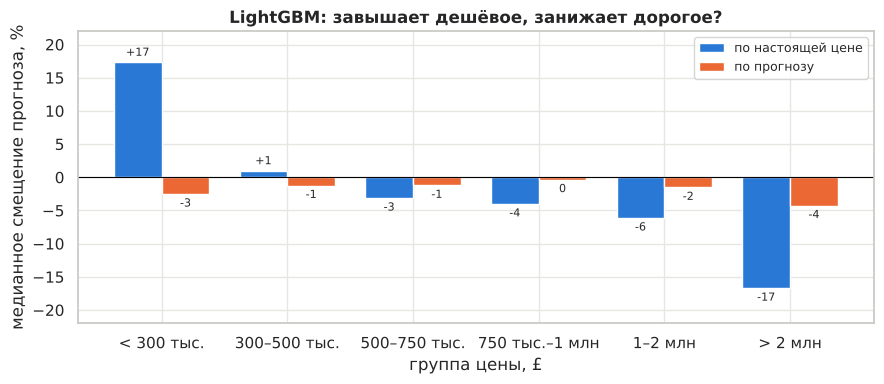

In [23]:
pg = err[(err['модель'] == 'LightGBM') & err['сегмент'].isin(['цена (реальная)', 'цена (прогноз)'])].copy()
order = ['< 300 тыс.', '300–500 тыс.', '500–750 тыс.', '750 тыс.–1 млн', '1–2 млн', '> 2 млн']
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(order))
for i, (s, c, lab) in enumerate((('цена (реальная)', BLUE, 'по настоящей цене'), ('цена (прогноз)', ORANGE, 'по прогнозу'))):
    d = pg[pg['сегмент'] == s].set_index('значение').loc[order]
    ax.bar(x + (i - 0.5) * 0.38, d['смещение_%'], width=0.38, color=c, label=lab)
    for xi, v in zip(x + (i - 0.5) * 0.38, d['смещение_%']):
        lab = f'{v:+.0f}' if abs(v) >= 0.5 else '0'
        ax.text(xi, v + (0.6 if v >= 0 else -0.6), lab, ha='center', va='bottom' if v >= 0 else 'top', fontsize=8)
ax.axhline(0, color='black', lw=0.8)
ax.set_xticks(x, order)
ax.set_ylim(-22, 22)
ax.set_ylabel('медианное смещение прогноза, %')
ax.set_xlabel('группа цены, £')
ax.set_title('LightGBM: завышает дешёвое, занижает дорогое?')
ax.legend(fontsize=9, loc='upper right')
plt.tight_layout()
plt.show()

> **Что за график.** Медианное смещение прогноза LightGBM (выше нуля — прогноз завышен) в группах по цене: синим — группы по **настоящей** цене, оранжевым — по **прогнозу**.
> **Что показывает.** Если группировать по настоящей цене, дешёвое жильё завышается (+17%), а дорогое (> 2 млн £) занижается (−17%). Это обычный эффект «притяжения к среднему»: в группу «дешевле 300 тыс.» попадают, в частности, объекты, проданные дешевле рынка, и их модель предсказать не может. Если группировать по прогнозу (так, как будет работать сервис: мы знаем только прогноз), смещение маленькое во всех группах (от −4% до 0%). Значит, систематического перекоса у модели почти нет; разброс же у самых дорогих объектов больше (MdAPE 17–20%).

In [24]:
br = err[(err['модель'] == 'LightGBM') & (err['сегмент'] == 'borough') & (err['n'] >= 500)].sort_values('RMSE_log')
br = pd.concat([br.head(3), br.tail(4)])[['значение', 'n', 'RMSE_log', 'MdAPE_%']]
br.columns = ['borough', 'n', 'RMSE_log', 'MdAPE, %']
br.style.format({'RMSE_log': '{:.3f}', 'MdAPE, %': '{:.1f}', 'n': '{:,.0f}'}).hide(axis='index')

borough,n,RMSE_log,"MdAPE, %"
Greenwich,"5,637",0.243,9.2
Croydon,"1,741",0.251,10.4
Lambeth,"7,489",0.269,10.0
Brent,"1,423",0.390,12.4
City of London,546,0.407,11.4
Kensington and Chelsea,"3,225",0.513,18.0
Westminster,"4,718",0.519,16.7


**Что видно.** По районам (borough, не меньше 500 продаж) лучше всего прогнозируются Croydon, Greenwich, Lambeth (RMSE_log 0,24–0,27, MdAPE 9–10%), хуже всего центральные дорогие районы — Kensington and Chelsea и Westminster (0,51–0,52, MdAPE 17–18%): там рядом стоят очень разные объекты (от студии до особняка), а площадь и комнаты мало говорят об отделке и виде из окна.

### 8.2 Важность признаков в LightGBM (SHAP)

SHAP показывает, насколько каждый признак сдвигает прогноз конкретного объекта вверх или вниз. Среднее модуля сдвига по объектам — важность признака. Считали на 3000 случайных продажах 2023 года (модель обучена до 2022).

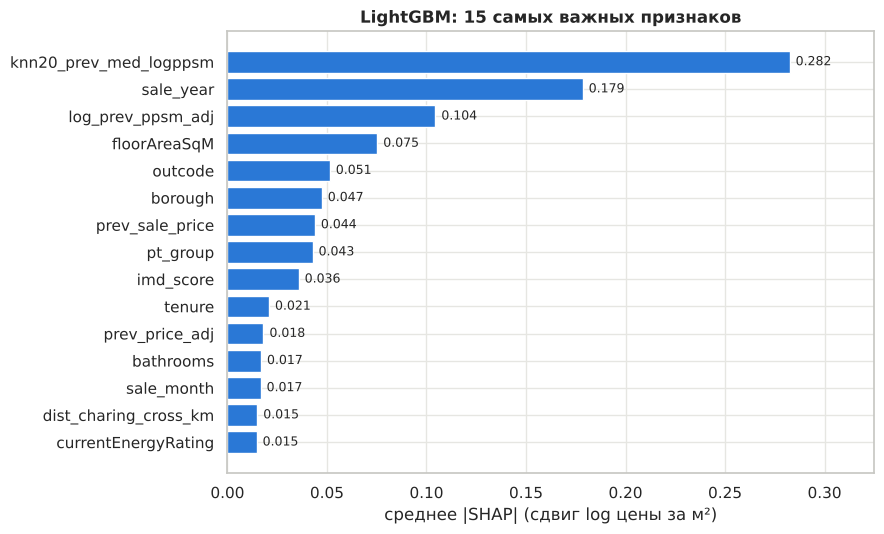

In [25]:
sh = imp[imp['источник'].str.startswith('LightGBM')].head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(sh['признак'], sh['значение'], color=BLUE)
for i, v in enumerate(sh['значение']):
    ax.text(v + 0.003, i, f'{v:.3f}', va='center', fontsize=9)
ax.set_xlim(0, sh['значение'].max() * 1.15)
ax.set_xlabel('среднее |SHAP| (сдвиг log цены за м²)')
ax.set_title('LightGBM: 15 самых важных признаков')
plt.tight_layout()
plt.show()

> **Что за график.** Средний модуль SHAP-значения: насколько в среднем признак сдвигает прогноз log(цены за м²). 0,1 ≈ сдвиг прогноза на 10%.
> **Что показывает.** Самые важные признаки: **цены 20 ближайших продаж за прошлый год** (`knn20_prev_med_logppsm`, 0,28) и **год продажи** (0,18; через него модель учит общий уровень цен). Дальше — цена м² прошлой продажи того же адреса (новый признак этого чекпойнта, 0,10), площадь, район (outcode, borough), прошлая цена, тип жилья и IMD. Это совпадает с абляцией чекпойнта 2: прошлая продажа и цены соседей — самые сильные группы, расстояния, транспорт и IMD дают меньший вклад.

Важно: модель на деревьях не умеет продолжать тренд за пределы лет, которые видела. Год продажи для 2024 модель воспринимает как «2023 и позже», поэтому если цены в 2024 году сильно изменятся, прогноз это не учтёт (пока уровень цен она берёт из цен соседей за 2023 год).

## 9. Гипотеза: чем больше площадь, тем ниже цена за м²

Простая линейная регрессия `log(цена за м²) = b · log(площади) + …` на всех «чистых» продажах train с известной площадью. Коэффициент b: если площадь вырастет на 1%, цена за м² изменится примерно на b%. Добавляем по одному «прочие равные»: год, район (outcode), тип жилья и другие характеристики. Это объясняющая модель на всех данных, а не прогноз.

In [26]:
area = rd('ml_area.csv')
area.style.format({'коэффициент при log площади': '{:+.3f}', 'изменение цены за м² при площади ×2, %': '{:+.1f}',
                   'n': '{:,.0f}'}).hide(axis='index')

период,модель,коэффициент при log площади,"изменение цены за м² при площади ×2, %",n
1995–2023,1. только площадь,-0.037,-2.5,"250,950"
1995–2023,2. + год продажи,-0.054,-3.6,"250,950"
1995–2023,3. + год и район (outcode),-0.081,-5.5,"250,950"
1995–2023,"4. + год, район, тип жилья",-0.166,-10.9,"250,950"
1995–2023,"5. + год, район, тип, спальни, энергокласс, tenure",-0.182,-11.8,"250,950"
2019–2023,1. только площадь,+0.058,+4.1,"92,593"
2019–2023,2. + год продажи,+0.059,+4.2,"92,593"
2019–2023,3. + год и район (outcode),+0.016,+1.1,"92,593"
2019–2023,"4. + год, район, тип жилья",-0.107,-7.1,"92,593"
2019–2023,"5. + год, район, тип, спальни, энергокласс, tenure",-0.130,-8.6,"92,593"


**Что видно.** Без учёта других факторов связь слабая и даже меняет знак (за 2019–2023: +4%, большие объекты чаще встречаются в дорогих районах). Когда сравниваем объекты **одного района, года и типа жилья**, гипотеза подтверждается: вдвое большая площадь — цена за м² ниже на 11–12% (1995–2023) и на 7–9% (2019–2023). Тот же знак у коэффициента площади в Ridge (раздел 5.4). Это связь в данных при прочих равных, а не доказанная причина (например, большие квартиры чаще на нижних этажах или в старом фонде — этих данных у нас нет).

## 10. Выводы и что дальше

**Метрика.** Ключевая метрика — RMSE по логарифму цены (в цене, после перевода прогноза цены за м² в цену): ошибка считается в долях, а не в фунтах, одинаково для дешёвого и дорогого жилья, не зависит от хвоста очень дорогих объектов и сравнима с чекпойнтом 2. Вспомогательные: MdAPE, доля прогнозов в ±10% и ±20%, MAE в £. Выбор нужно согласовать с куратором.

**Цель.** Модели предсказывают log(цены за м²), прогноз цены = exp(прогноз) × площадь. Проверка: та же лучшая модель с целью log(цены) даёт то же качество (0,3469 против 0,3468).

**Итоговое сравнение (RMSE_log, среднее 2021–2023; MdAPE; доля в ±20%):**

| Модель | RMSE_log | MdAPE | в ±20% |
|---|---|---|---|
| 0а. Медиана цены м² района × площадь | 0,416 | 16,5% | 58% |
| KNN: окно 5 лет, 13 признаков, k = 20, веса по расстоянию | 0,375 | 13,4% | 67% |
| Ridge: признаки + квадраты, обучение на 10 годах | 0,369 | 12,7% | 69% |
| **LightGBM: подбор + признаки** | **0,347** | **11,1%** | **74%** |

**Что дал подбор гиперпараметров и feature engineering.**
- KNN: 0,905 → 0,375. Главное — работа с данными и признаками: соседи только из последних 5 лет (старые цены мешают), полный набор признаков (место, объект, окружение, прошлая продажа). Подбор k (20) и весов (`distance`) дал ещё −0,012.
- Линейные модели: 0,484 → 0,369. Главное — признаки чекпойнта 2 (цены соседей, прошлая продажа), отказ от линейного тренда по годам, квадраты и взаимодействия, обучение на последних 10 годах. Подбор alpha почти ничего не меняет (данных много, переобучения нет); LinearRegression, Ridge и Lasso дают одно и то же.
- LightGBM: 0,361 → 0,347. Главное — подбор гиперпараметров (−0,014; выбран по 2021–2022 и подтверждён на 2023), новые признаки (цена м² прошлой продажи, флаг «адрес на несколько квартир» по прошлому) — ещё −0,0005.
- Не помогло: заполнение пропусков для бустинга (деревьям лучше `NaN`), флаги пропусков, вес координат у KNN.

**Анализ ошибок.** Самые большие промахи — ошибки в самих данных (96 из 100 крупнейших — подозрительные цены). Хуже всего прогнозируются объекты без площади (MdAPE 23%), без прошлой продажи (14%), адреса на несколько квартир (17%), отдельные дома и центральные дорогие районы (Kensington and Chelsea, Westminster: 17–18%). Систематического смещения по группам прогноза почти нет.

**Влияние факторов.** Цена за м² сильнее всего зависит от уровня цен соседей, истории продаж адреса, расстояния до центра, индекса депривации, типа жилья (квартира дешевле за м², чем отдельный дом, примерно на 19%) и площади (больше площадь — дешевле метр: −11–12% при удвоении площади в том же районе, году и типе жилья).

**Открытые вопросы (обсудить с куратором).**
- Согласовать ключевую метрику.
- Отбор строк для обучения: без подозрительных цен модель лучше на обычном жилье (RMSE 0,280 против 0,282, MdAPE 11,1% против 11,4%), но ключевая метрика на всех строках лучше при обучении на всех строках (0,344 против 0,347). Правило `price_suspect_noarea` по ключевой метрике не помогает.
- Модель на деревьях не продолжает тренд цен за пределы 2023 года.

**Что дальше (чекпойнт 4 и позже).**
- Сервис на FastAPI на основе LightGBM (`models/lgbm_final.txt`): цена, диапазон (квантильные модели с калибровкой по прошлому году — пробовали в черновике, вернёмся на чекпойнте 4), объяснение факторов через SHAP, похожие продажи рядом (тот же KNN по координатам и признакам).
- Новые данные: EPC (этаж, возраст дома), школы и парки, индекс цен UK HPI (для тренда), таблица соответствия LSOA 2011 → 2021 (пропуски IMD в test).
- Прогноз для test 2024 сохранён в `reports/test_predictions.csv` (модель обучена на всём train 1995–2023).

## 11. Как воспроизвести

Из корня репозитория:

```bash
pip install -r requirements.txt
python src/build_dataset.py      # основная база data/processed/*_enriched.csv (~1 мин)
python src/train_models.py       # все расчёты (~30 мин на 4 ядрах): reports/ml_*.csv, models/lgbm_final.txt
# или по шагам: --stage folds | baselines | knn | linear | lgb | analysis | final
cd notebooks && jupyter nbconvert --to notebook --execute --inplace ML.ipynb
```

Фолды кэшируются в `data/processed/folds/` (если база пересобрана, папку нужно удалить). Код: `src/ml_utils.py` (фолды, признаки, метрики, модели), `src/train_models.py` (расчёты по шагам).